Imports e Paths

In [145]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [146]:
PROJECT_ROOT = Path.cwd().parent

DATASET_PATH = PROJECT_ROOT / "data" / "processed" / "dataset.csv"

PREDICTIONS_PATH = (
    PROJECT_ROOT / "outputs" / "predictions" / "part2_naive_bayes_predictions.csv"
)
CALIBRATED_PREDICTIONS_PATH = (
    PROJECT_ROOT / "outputs" / "predictions" / "part2_naive_bayes_calibrated_predictions.csv"
)

OUTPUT_DIR = PROJECT_ROOT / "outputs"
METRICS_DIR = OUTPUT_DIR / "metrics"
PREDICTIONS_DIR = OUTPUT_DIR / "predictions"
FIGURES_DIR = OUTPUT_DIR / "figures"

for folder in [METRICS_DIR, PREDICTIONS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print(DATASET_PATH.exists())
print(PREDICTIONS_PATH.exists())

True
True


Carregar Dataset e Previsões

In [147]:
CLASSES = ["A", "D", "H"]

df = pd.read_csv(DATASET_PATH, parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)

n = len(df)
train_end = int(n * 0.6)
cal_end = int(n * 0.8)

test_df = df.iloc[cal_end:].copy().reset_index(drop=True)

preds = pd.read_csv(PREDICTIONS_PATH, parse_dates=["date"])
preds = preds.reset_index(drop=True)

print(test_df.shape)
print(preds.shape)

test_part3 = test_df[
    [
        "date",
        "ht",
        "at",
        "result",
        "h_odds",
        "d_odds",
        "a_odds",
    ]
].copy()

for cls in CLASSES:
    test_part3[f"p_model_{cls}"] = preds[f"p_{cls}"]

test_part3["model_pred"] = preds["predicted_result"]

test_part3.head(10)

(1117, 31)
(1117, 6)


,date,ht,at,result,h_odds,d_odds,a_odds,p_model_A,p_model_D,p_model_H,model_pred
0,2022-04-25,boavista,sporting,A,7.00,4.20,1.44,0.778332,0.170804,0.050864,A
1,2022-04-25,sp braga,porto,H,4.00,3.60,1.80,0.945773,0.047287,0.006940,A
2,2022-04-29,famalicao,estoril,H,1.75,3.60,4.50,0.206279,0.353077,0.440643,H
3,2022-04-30,belenenses,sp braga,A,5.00,3.75,1.70,0.725238,0.208730,0.066032,A
4,2022-04-30,arouca,portimonense,H,1.95,3.30,3.80,0.140994,0.417932,0.441074,H
5,2022-04-30,maritimo,benfica,A,6.00,4.20,1.53,0.747581,0.149822,0.102597,A
6,2022-04-30,porto,vizela,H,1.12,8.00,19.00,0.006665,0.046370,0.946965,H
7,2022-05-01,sporting,gil vicente,H,1.33,5.50,8.50,0.000851,0.012463,0.986686,H
8,2022-05-01,guimaraes,santa clara,D,1.90,3.50,4.00,0.173157,0.361473,0.465370,H
9,2022-05-01,moreirense,boavista,A,2.20,3.30,3.30,0.140994,0.417932,0.441074,H


Comparar Modelo vs Odd

In [148]:
def add_model_vs_odds_disagreement(df):
    out = df.copy()

    for cls in CLASSES:
        out[f"diff_{cls}"] = out[f"p_model_{cls}"] - out[f"p_odds_{cls}"]

    out["max_abs_diff"] = out[[f"diff_{cls}" for cls in CLASSES]].abs().max(axis=1)
    out["model_disagrees_with_odds"] = out["model_pred"] != out["odds_pred"]

    return out

def add_implied_probabilities(df):
    out = df.copy()

    out["p_raw_H"] = 1 / out["h_odds"]
    out["p_raw_D"] = 1 / out["d_odds"]
    out["p_raw_A"] = 1 / out["a_odds"]

    out["bookmaker_margin"] = out[["p_raw_H", "p_raw_D", "p_raw_A"]].sum(axis=1)

    out["p_odds_H"] = out["p_raw_H"] / out["bookmaker_margin"]
    out["p_odds_D"] = out["p_raw_D"] / out["bookmaker_margin"]
    out["p_odds_A"] = out["p_raw_A"] / out["bookmaker_margin"]

    out["odds_pred"] = out[["p_odds_A", "p_odds_D", "p_odds_H"]].idxmax(axis=1)
    out["odds_pred"] = out["odds_pred"].str.replace("p_odds_", "", regex=False)

    return out

test_part3 = add_implied_probabilities(test_part3)

test_part3 = add_model_vs_odds_disagreement(test_part3)

disagreement_summary = {
    "mean_max_abs_diff": test_part3["max_abs_diff"].mean(),
    "median_max_abs_diff": test_part3["max_abs_diff"].median(),
    "disagreement_rate": test_part3["model_disagrees_with_odds"].mean(),
}

disagreement_summary

{'mean_max_abs_diff': np.float64(0.20458354376690707),
 'median_max_abs_diff': np.float64(0.1807677346065315),
 'disagreement_rate': np.float64(0.26857654431512984)}

In [149]:
top_disagreements = test_part3.sort_values(
    "max_abs_diff",
    ascending=False,
).head(20)

top_disagreements[
    [
        "date", "ht", "at", "result",
        "model_pred", "odds_pred",
        "p_model_H", "p_odds_H",
        "p_model_D", "p_odds_D",
        "p_model_A", "p_odds_A",
        "max_abs_diff",
    ]
]

,date,ht,at,result,model_pred,odds_pred,p_model_H,p_odds_H,p_model_D,p_odds_D,p_model_A,p_odds_A,max_abs_diff
803,2025-01-25,casa pia,benfica,H,H,A,0.879908,0.111746,0.087464,0.199966,0.032628,0.688288,0.768162
472,2024-01-06,arouca,benfica,A,H,A,0.876412,0.159664,0.085871,0.201681,0.037716,0.638655,0.716748
426,2023-11-11,guimaraes,porto,A,H,A,0.902424,0.189591,0.073382,0.252788,0.024194,0.557621,0.712833
815,2025-02-01,santa clara,casa pia,H,A,H,0.010196,0.448420,0.084449,0.303769,0.905355,0.247811,0.657544
301,2023-05-06,benfica,sp braga,H,A,H,0.053171,0.605743,0.133063,0.223548,0.813765,0.170709,0.643056
457,2023-12-17,sp braga,benfica,A,H,A,0.945109,0.311193,0.048700,0.282903,0.006191,0.405904,0.633916
833,2025-02-15,nacional,estoril,D,A,H,0.033106,0.419297,0.062654,0.294818,0.904241,0.285884,0.618356
386,2023-09-24,sp braga,boavista,H,A,H,0.142917,0.615385,0.087931,0.230769,0.769152,0.153846,0.615306
971,2025-08-29,gil vicente,moreirense,H,A,H,0.012694,0.366725,0.092893,0.331613,0.894413,0.301661,0.592752
480,2024-01-13,estoril,moreirense,A,H,H,0.969918,0.389704,0.028051,0.287782,0.002031,0.322514,0.580214


In [150]:
top_disagreements.to_csv(
    PREDICTIONS_DIR / "part3_top_model_odds_disagreements.csv",
    index=False,
)

Calcular Expected Value das Apostas

In [151]:
def add_expected_values(df):
    out = df.copy()

    out["ev_H"] = out["p_model_H"] * out["h_odds"] - 1
    out["ev_D"] = out["p_model_D"] * out["d_odds"] - 1
    out["ev_A"] = out["p_model_A"] * out["a_odds"] - 1

    ev_cols = ["ev_A", "ev_D", "ev_H"]

    out["best_ev"] = out[ev_cols].max(axis=1)
    out["best_ev_bet"] = out[ev_cols].idxmax(axis=1).str.replace("ev_", "", regex=False)

    out["bet_decision"] = np.where(
        out["best_ev"] > 0,
        out["best_ev_bet"],
        "NO_BET",
    )

    return out


test_part3 = add_expected_values(test_part3)

test_part3[
    [
        "date", "ht", "at", "result",
        "p_model_H", "p_model_D", "p_model_A",
        "h_odds", "d_odds", "a_odds",
        "ev_H", "ev_D", "ev_A",
        "best_ev", "bet_decision",
    ]
].head(10)

,date,ht,at,result,p_model_H,p_model_D,p_model_A,h_odds,d_odds,a_odds,ev_H,ev_D,ev_A,best_ev,bet_decision
0,2022-04-25,boavista,sporting,A,0.050864,0.170804,0.778332,7.00,4.20,1.44,-0.643952,-0.282624,0.120798,0.120798,A
1,2022-04-25,sp braga,porto,H,0.006940,0.047287,0.945773,4.00,3.60,1.80,-0.972239,-0.829767,0.702391,0.702391,A
2,2022-04-29,famalicao,estoril,H,0.440643,0.353077,0.206279,1.75,3.60,4.50,-0.228874,0.271078,-0.071743,0.271078,D
3,2022-04-30,belenenses,sp braga,A,0.066032,0.208730,0.725238,5.00,3.75,1.70,-0.669841,-0.217262,0.232905,0.232905,A
4,2022-04-30,arouca,portimonense,H,0.441074,0.417932,0.140994,1.95,3.30,3.80,-0.139905,0.379176,-0.464224,0.379176,D
5,2022-04-30,maritimo,benfica,A,0.102597,0.149822,0.747581,6.00,4.20,1.53,-0.384418,-0.370748,0.143799,0.143799,A
6,2022-04-30,porto,vizela,H,0.946965,0.046370,0.006665,1.12,8.00,19.00,0.060601,-0.629040,-0.873368,0.060601,H
7,2022-05-01,sporting,gil vicente,H,0.986686,0.012463,0.000851,1.33,5.50,8.50,0.312293,-0.931454,-0.992768,0.312293,H
8,2022-05-01,guimaraes,santa clara,D,0.465370,0.361473,0.173157,1.90,3.50,4.00,-0.115797,0.265156,-0.307372,0.265156,D
9,2022-05-01,moreirense,boavista,A,0.441074,0.417932,0.140994,2.20,3.30,3.30,-0.029636,0.379176,-0.534721,0.379176,D


Simulação de Apostas

In [152]:
def simulate_betting_strategy(df, decision_col="bet_decision", stake=1.0):
    out = df.copy()

    def profit(row):
        decision = row[decision_col]

        if decision == "NO_BET":
            return 0.0

        if decision == row["result"]:
            if decision == "H":
                return row["h_odds"] * stake - stake
            if decision == "D":
                return row["d_odds"] * stake - stake
            if decision == "A":
                return row["a_odds"] * stake - stake

        return -stake

    out["profit"] = out.apply(profit, axis=1)
    out["placed_bet"] = out[decision_col] != "NO_BET"
    out["correct_bet"] = out[decision_col] == out["result"]

    n_matches = len(out)
    n_bets = int(out["placed_bet"].sum())
    total_profit = out["profit"].sum()
    total_staked = n_bets * stake

    summary = {
        "n_matches": n_matches,
        "n_bets": n_bets,
        "bet_rate": n_bets / n_matches if n_matches > 0 else 0,
        "hit_rate": out.loc[out["placed_bet"], "correct_bet"].mean() if n_bets > 0 else np.nan,
        "total_profit": total_profit,
        "total_staked": total_staked,
        "roi": total_profit / total_staked if total_staked > 0 else np.nan,
        "profit_per_match": total_profit / n_matches if n_matches > 0 else 0,
    }

    return out, summary


betting_results, betting_summary = simulate_betting_strategy(test_part3)

betting_summary

{'n_matches': 1117,
 'n_bets': 1107,
 'bet_rate': 0.991047448522829,
 'hit_rate': np.float64(0.45709123757904246),
 'total_profit': np.float64(-75.14000000000001),
 'total_staked': 1107.0,
 'roi': np.float64(-0.06787714543812107),
 'profit_per_match': np.float64(-0.06726947179946285)}

In [153]:
betting_results.to_csv(
    PREDICTIONS_DIR / "part3_betting_simulation.csv",
    index=False,
)

pd.DataFrame([betting_summary]).to_csv(
    METRICS_DIR / "part3_betting_summary.csv",
    index=False,
)

Baseline: Apostar Sempre no Favorito das Odds

In [154]:
def add_odds_favorite_decision(df):
    out = df.copy()

    odds_cols = ["h_odds", "d_odds", "a_odds"]

    # menor odd = favorito
    out["odds_favorite_bet"] = out[odds_cols].idxmin(axis=1)
    out["odds_favorite_bet"] = (
        out["odds_favorite_bet"]
        .str.replace("h_odds", "H", regex=False)
        .str.replace("d_odds", "D", regex=False)
        .str.replace("a_odds", "A", regex=False)
    )

    return out


test_part3 = add_odds_favorite_decision(test_part3)

odds_fav_results, odds_fav_summary = simulate_betting_strategy(
    test_part3,
    decision_col="odds_favorite_bet",
)

odds_fav_summary

{'n_matches': 1117,
 'n_bets': 1117,
 'bet_rate': 1.0,
 'hit_rate': np.float64(0.5935541629364369),
 'total_profit': np.float64(36.20999999999999),
 'total_staked': 1117.0,
 'roi': np.float64(0.03241718889883616),
 'profit_per_match': np.float64(0.03241718889883616)}

Comparação

In [155]:
strategy_comparison = pd.DataFrame([
    {
        "strategy": "model_positive_ev",
        **betting_summary,
    },
    {
        "strategy": "always_bet_odds_favorite",
        **odds_fav_summary,
    },
])

strategy_comparison.to_csv(
    METRICS_DIR / "part3_strategy_comparison.csv",
    index=False,
)

strategy_comparison

,strategy,n_matches,n_bets,bet_rate,hit_rate,total_profit,total_staked,roi,profit_per_match
0,model_positive_ev,1117,1107,0.991047,0.457091,-75.14,1107.0,-0.067877,-0.067269
1,always_bet_odds_favorite,1117,1117,1.000000,0.593554,36.21,1117.0,0.032417,0.032417


Reject Option

In [156]:
def add_reject_option(df, theta=0.5):
    out = df.copy()

    model_prob_cols = ["p_model_A", "p_model_D", "p_model_H"]

    out["model_confidence"] = out[model_prob_cols].max(axis=1)
    out["reject"] = out["model_confidence"] < theta

    out["reject_decision"] = np.where(
        out["reject"],
        "NO_BET",
        out["bet_decision"],
    )

    return out


theta = 0.50

reject_df = add_reject_option(test_part3, theta=theta)

reject_results, reject_summary = simulate_betting_strategy(
    reject_df,
    decision_col="reject_decision",
)

reject_summary

{'n_matches': 1117,
 'n_bets': 681,
 'bet_rate': 0.6096687555953447,
 'hit_rate': np.float64(0.5609397944199707),
 'total_profit': np.float64(-47.330000000000005),
 'total_staked': 681.0,
 'roi': np.float64(-0.06950073421439061),
 'profit_per_match': np.float64(-0.04237242614145032)}

Testar Vários Thresholds

In [157]:
thresholds = np.arange(0.34, 0.81, 0.02)

rows = []

for theta in thresholds:
    tmp = add_reject_option(test_part3, theta=theta)

    tmp_results, tmp_summary = simulate_betting_strategy(
        tmp,
        decision_col="reject_decision",
    )

    rows.append({
        "theta": theta,
        **tmp_summary,
    })

reject_curve = pd.DataFrame(rows)

reject_curve.to_csv(
    METRICS_DIR / "part3_reject_threshold_curve.csv",
    index=False,
)

reject_curve.head()

,theta,n_matches,n_bets,bet_rate,hit_rate,total_profit,total_staked,roi,profit_per_match
0,0.34,1117,1107,0.991047,0.457091,-75.14,1107.0,-0.067877,-0.067269
1,0.36,1117,1096,0.981200,0.461679,-64.14,1096.0,-0.058522,-0.057422
2,0.38,1117,1087,0.973142,0.462741,-64.94,1087.0,-0.059742,-0.058138
3,0.40,1117,1047,0.937332,0.464183,-82.87,1047.0,-0.079150,-0.074190
4,0.42,1117,958,0.857654,0.467641,-115.07,958.0,-0.120115,-0.103017


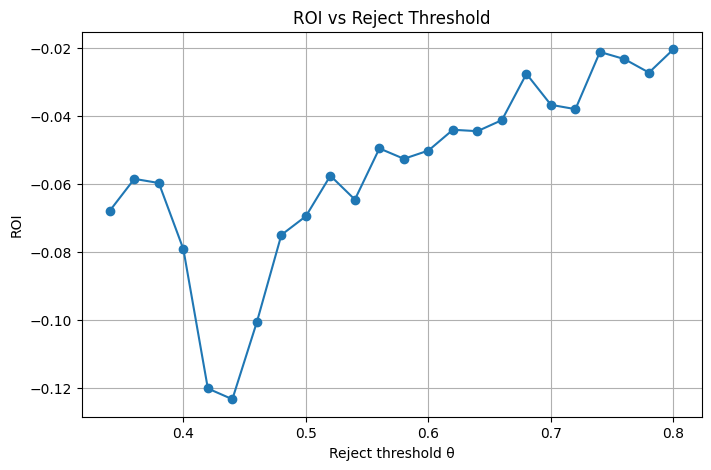

In [158]:
plt.figure(figsize=(8, 5))
plt.plot(reject_curve["theta"], reject_curve["roi"], marker="o")
plt.xlabel("Reject threshold θ")
plt.ylabel("ROI")
plt.title("ROI vs Reject Threshold")
plt.grid(True)
plt.savefig(FIGURES_DIR / "part3_roi_vs_reject_threshold.png", bbox_inches="tight", dpi=150)
plt.show()

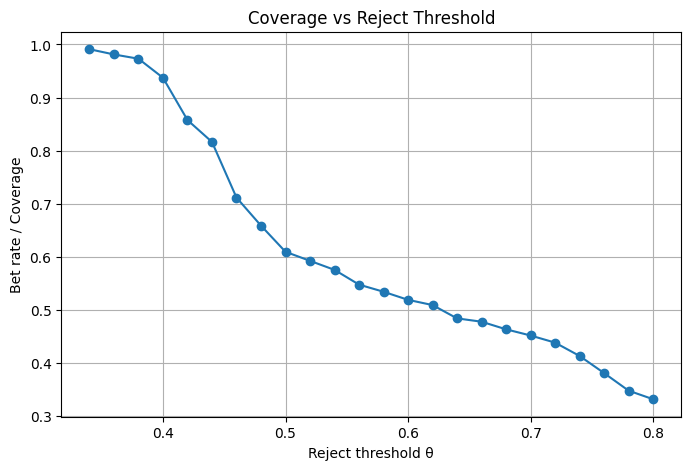

In [159]:
plt.figure(figsize=(8, 5))
plt.plot(reject_curve["theta"], reject_curve["bet_rate"], marker="o")
plt.xlabel("Reject threshold θ")
plt.ylabel("Bet rate / Coverage")
plt.title("Coverage vs Reject Threshold")
plt.grid(True)
plt.savefig(FIGURES_DIR / "part3_coverage_vs_reject_threshold.png", bbox_inches="tight", dpi=150)
plt.show()

Deferir para odds em vez de rejeitar

In [160]:
def add_defer_to_odds_strategy(df, theta=0.5):
    out = df.copy()

    model_prob_cols = ["p_model_A", "p_model_D", "p_model_H"]

    out["model_confidence"] = out[model_prob_cols].max(axis=1)
    out["defer_to_odds"] = out["model_confidence"] < theta

    out["defer_decision"] = np.where(
        out["defer_to_odds"],
        out["odds_favorite_bet"],
        out["bet_decision"],
    )

    return out


defer_df = add_defer_to_odds_strategy(test_part3, theta=theta)

defer_results, defer_summary = simulate_betting_strategy(
    defer_df,
    decision_col="defer_decision",
)

defer_summary

{'n_matches': 1117,
 'n_bets': 1114,
 'bet_rate': 0.9973142345568488,
 'hit_rate': np.float64(0.5816876122082585),
 'total_profit': np.float64(17.869999999999997),
 'total_staked': 1114.0,
 'roi': np.float64(0.016041292639138238),
 'profit_per_match': np.float64(0.015998209489704564)}

In [161]:
final_strategy_comparison = pd.DataFrame([
    {
        "strategy": "model_positive_ev",
        **betting_summary,
    },
    {
        "strategy": "always_bet_odds_favorite",
        **odds_fav_summary,
    },
    {
        "strategy": f"reject_if_confidence_below_{theta}",
        **reject_summary,
    },
    {
        "strategy": f"defer_to_odds_if_confidence_below_{theta}",
        **defer_summary,
    },
])

final_strategy_comparison.to_csv(
    METRICS_DIR / "part3_final_strategy_comparison.csv",
    index=False,
)

final_strategy_comparison

,strategy,n_matches,n_bets,bet_rate,hit_rate,total_profit,total_staked,roi,profit_per_match
0,model_positive_ev,1117,1107,0.991047,0.457091,-75.14,1107.0,-0.067877,-0.067269
1,always_bet_odds_favorite,1117,1117,1.000000,0.593554,36.21,1117.0,0.032417,0.032417
2,reject_if_confidence_below_0.8000000000000005,1117,681,0.609669,0.560940,-47.33,681.0,-0.069501,-0.042372
3,defer_to_odds_if_confidence_below_0.8000000000...,1117,1114,0.997314,0.581688,17.87,1114.0,0.016041,0.015998


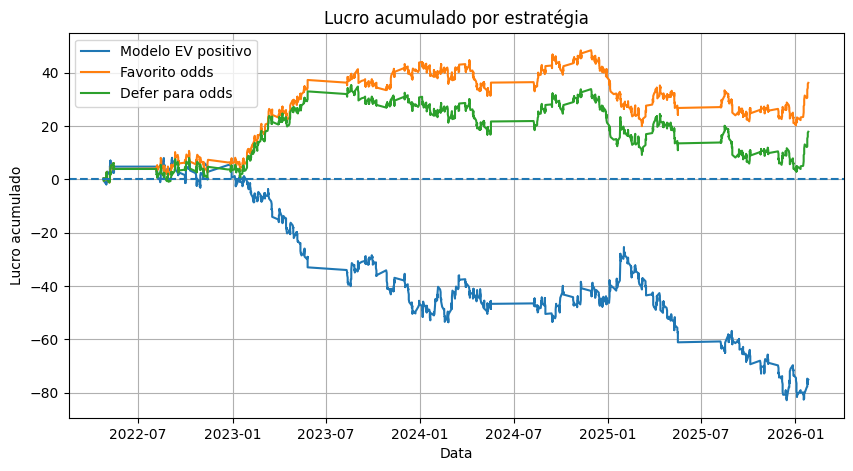

In [162]:
import matplotlib.pyplot as plt

def profit_for_decision(row, decision_col, stake=1.0):
    decision = row[decision_col]

    if decision == "NO_BET":
        return 0.0

    if decision == row["result"]:
        if decision == "H":
            return row["h_odds"] * stake - stake
        if decision == "D":
            return row["d_odds"] * stake - stake
        if decision == "A":
            return row["a_odds"] * stake - stake

    return -stake


plot_df = test_part3.copy()

plot_df["profit_model_ev"] = plot_df.apply(
    lambda row: profit_for_decision(row, "bet_decision"),
    axis=1
)

plot_df["profit_odds_favorite"] = plot_df.apply(
    lambda row: profit_for_decision(row, "odds_favorite_bet"),
    axis=1
)

defer_df = add_defer_to_odds_strategy(test_part3, theta=0.80)
plot_df["defer_decision"] = defer_df["defer_decision"]
plot_df["profit_defer"] = plot_df.apply(
    lambda row: profit_for_decision(row, "defer_decision"),
    axis=1
)

plot_df["cum_profit_model_ev"] = plot_df["profit_model_ev"].cumsum()
plot_df["cum_profit_odds_favorite"] = plot_df["profit_odds_favorite"].cumsum()
plot_df["cum_profit_defer"] = plot_df["profit_defer"].cumsum()

plt.figure(figsize=(10, 5))
plt.plot(plot_df["date"], plot_df["cum_profit_model_ev"], label="Modelo EV positivo")
plt.plot(plot_df["date"], plot_df["cum_profit_odds_favorite"], label="Favorito odds")
plt.plot(plot_df["date"], plot_df["cum_profit_defer"], label="Defer para odds")
plt.axhline(0, linestyle="--")
plt.xlabel("Data")
plt.ylabel("Lucro acumulado")
plt.title("Lucro acumulado por estratégia")
plt.legend()
plt.grid(True)
plt.savefig(FIGURES_DIR / "part3_cumulative_profit_by_strategy.png", bbox_inches="tight", dpi=150)
plt.show()

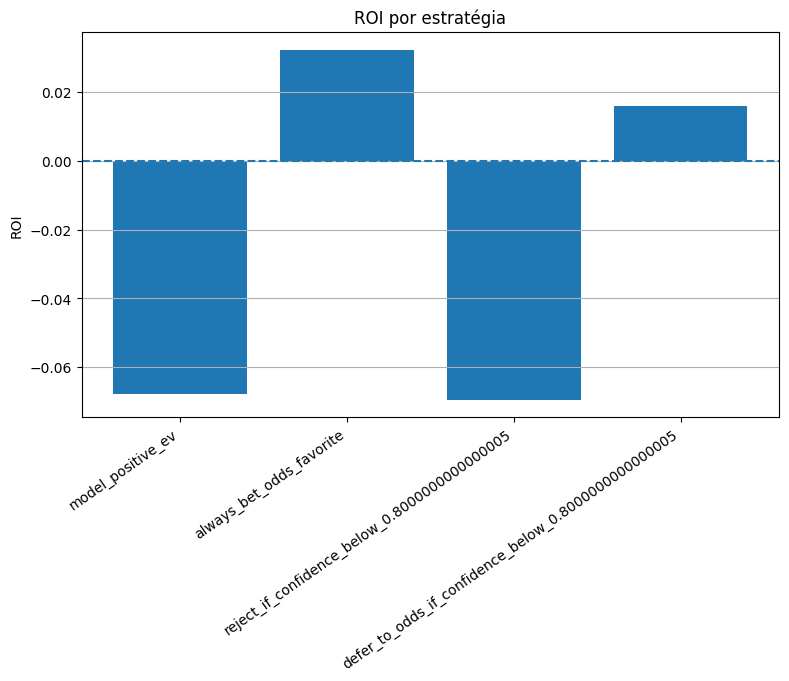

In [163]:
strategy_comparison = pd.read_csv(METRICS_DIR / "part3_final_strategy_comparison.csv")

plt.figure(figsize=(9, 5))
plt.bar(strategy_comparison["strategy"], strategy_comparison["roi"])
plt.axhline(0, linestyle="--")
plt.xticks(rotation=35, ha="right")
plt.ylabel("ROI")
plt.title("ROI por estratégia")
plt.grid(axis="y")
plt.savefig(FIGURES_DIR / "part3_roi_by_strategy.png", bbox_inches="tight", dpi=150)
plt.show()

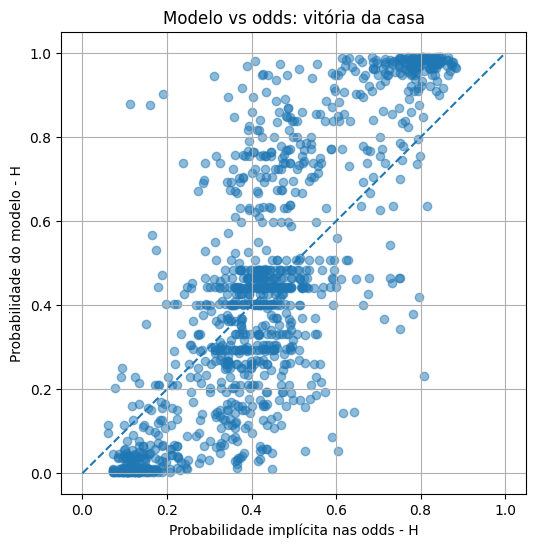

In [164]:
sim = pd.read_csv(PREDICTIONS_DIR / "part3_betting_simulation.csv")

plt.figure(figsize=(6, 6))
plt.scatter(sim["p_odds_H"], sim["p_model_H"], alpha=0.5)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("Probabilidade implícita nas odds - H")
plt.ylabel("Probabilidade do modelo - H")
plt.title("Modelo vs odds: vitória da casa")
plt.grid(True)
plt.savefig(FIGURES_DIR / "part3_model_vs_odds_home_probability.png", bbox_inches="tight", dpi=150)
plt.show()